# Urban Pulse: the 15 analyst tasks

NYC 311 service requests, created in 2024 (about 3% systematic sample, 103,841 rows, extracted 11 Nov 2026).
Every task has the question, the SQL (kept in `sql/analysis.sql`), the sample size, a chart, what we see and a careful reading of it.

Things to keep in mind for all tasks:
- "Closed" in this project means a closed date is recorded. It says nothing about whether the citizen was satisfied.
- Resolution time is only calculated when the closed date exists and is not before the created date (101,965 requests).
- The data is a sample of reported requests, so counts are roughly 1/33 of the real totals.

In [1]:
import re, sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from db import get_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

engine = get_engine()

# read the queries out of sql/analysis.sql, keyed by their "-- name:" line
sql_text = open("../sql/analysis.sql").read()
parts = re.split(r"^-- name: (\w+)\s*$", sql_text, flags=re.M)
QUERIES = dict(zip(parts[1::2], parts[2::2]))

def run(name):
    return pd.read_sql(text(QUERIES[name]), engine)

print(len(QUERIES), "queries loaded")

20 queries loaded


## Task 1. Total distinct request volume
**Question:** how many different requests are in the data?
**Method:** `COUNT(DISTINCT unique_key)` on `service_requests`.

In [2]:
t1 = run("t01_total_volume")
t1

,distinct_requests,rows_in_table
0,103841,103841


**Sample size:** whole table.
**Observed pattern:** 103,841 distinct requests and 103,841 rows, so there are no duplicate keys.
**Interpretation:** the table is clean on the key. Because this is a ~3% sample, the real citywide count for 2024 is about 3.46 million requests (the API count we saw during extraction).

## Task 2. Top 10 complaint categories
**Question:** what do people complain about most?
**Method:** group by `complaint_type`, count, sort, top 10.

,complaint_type,requests,pct_of_all
0,Illegal Parking,15247,14.68
1,Noise - Residential,11411,10.99
2,HEAT/HOT WATER,7942,7.65
3,Blocked Driveway,5088,4.90
4,Noise - Street/Sidewalk,4900,4.72
5,UNSANITARY CONDITION,3605,3.47
6,Abandoned Vehicle,2161,2.08
7,PLUMBING,2072,2.00
8,Street Condition,2071,1.99
9,Noise - Commercial,2015,1.94


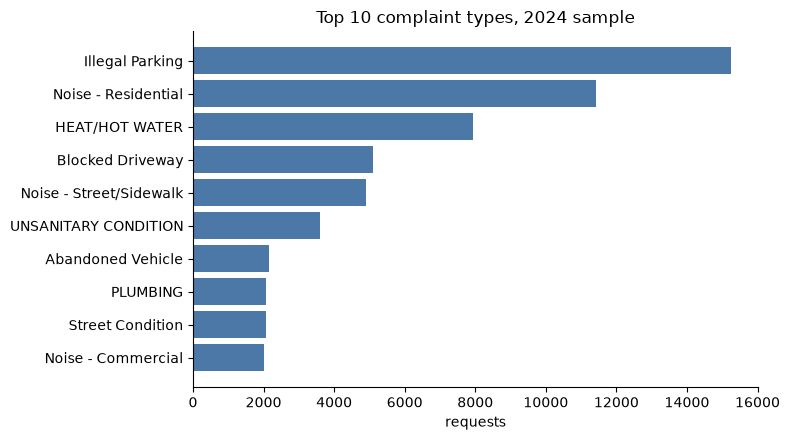

In [3]:
t2 = run("t02_top_complaints")
display(t2)
fig, ax = plt.subplots()
ax.barh(t2["complaint_type"][::-1], t2["requests"][::-1], color="#4c78a8")
ax.set_xlabel("requests")
ax.set_title("Top 10 complaint types, 2024 sample")
plt.tight_layout()
plt.show()

**Sample size:** 103,841 requests, 171 complaint types.
**Observed pattern:** Illegal Parking (14.7%) and Noise - Residential (11.0%) are the two biggest, then HEAT/HOT WATER (7.7%). The top 10 together are roughly 54% of all requests. Three of the top 10 are noise types.
**Interpretation:** demand is concentrated in a few everyday issues, mostly street and neighbourhood problems. The labels HEAT/HOT WATER and UNSANITARY CONDITION come in capital letters because that is how the source writes them, not because they are different kinds of record.

## Task 3. Agency workload
**Question:** which agencies receive the most requests?
**Method:** group by `agency`, count and share of total.

,agency,agency_name,requests,pct_of_all
0,NYPD,New York City Police Department,46538,44.82
1,HPD,Department of Housing Preservation and Develop...,21994,21.18
2,DSNY,Department of Sanitation,9213,8.87
3,DOT,Department of Transportation,6136,5.91
4,DEP,Department of Environmental Protection,5790,5.58
5,DPR,Department of Parks and Recreation,4199,4.04
6,DOB,Department of Buildings,3072,2.96
7,DOHMH,Department of Health and Mental Hygiene,2692,2.59
8,DHS,Department of Homeless Services,1511,1.46
9,TLC,Taxi and Limousine Commission,1156,1.11


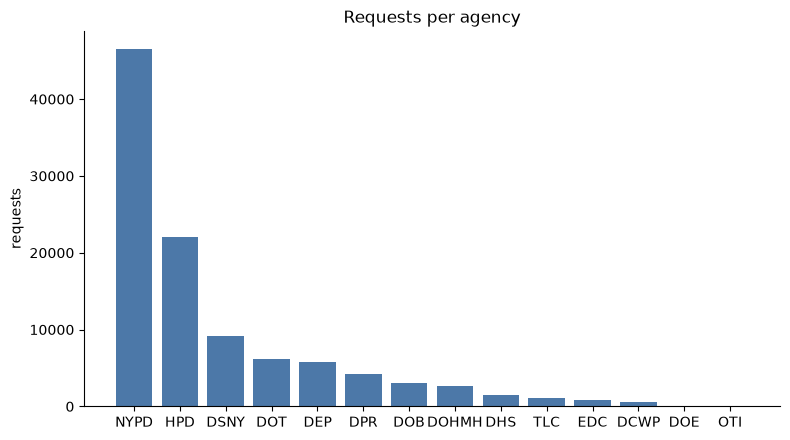

In [4]:
t3 = run("t03_agency_workload")
display(t3)
fig, ax = plt.subplots()
ax.bar(t3["agency"], t3["requests"], color="#4c78a8")
ax.set_ylabel("requests")
ax.set_title("Requests per agency")
plt.tight_layout()
plt.show()

**Sample size:** 103,841 requests, 14 agencies.
**Observed pattern:** NYPD gets 44.8% of requests and HPD 21.2%. Together with DSNY (8.9%) they hold about three quarters of the workload. The smallest agencies have under 1% each.
**Interpretation:** the recorded workload is very uneven. NYPD volume is mostly parking and noise reports, which are quick to record, so request counts do not equal effort. Compare agencies carefully.

## Task 4. Request volume by borough
**Question:** where do requests come from?
**Method:** group by `borough`.

,borough,requests,pct_of_all
0,BROOKLYN,31479,30.31
1,QUEENS,24831,23.91
2,BRONX,22305,21.48
3,MANHATTAN,21481,20.69
4,STATEN ISLAND,3657,3.52
5,UNSPECIFIED,88,0.08


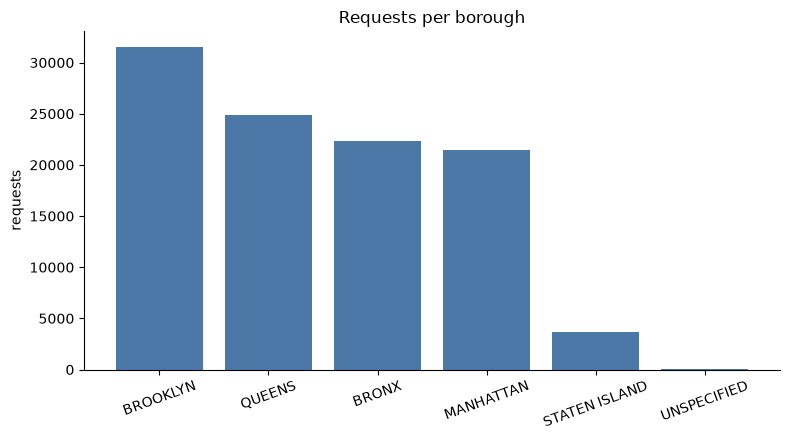

In [5]:
t4 = run("t04_borough_volume")
display(t4)
fig, ax = plt.subplots()
ax.bar(t4["borough"], t4["requests"], color="#4c78a8")
ax.set_ylabel("requests")
ax.set_title("Requests per borough")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Sample size:** 103,841 requests (88 rows have borough UNSPECIFIED).
**Observed pattern:** Brooklyn 30.3%, Queens 23.9%, Bronx 21.5%, Manhattan 20.7%, Staten Island 3.5%.
**Interpretation:** these are raw counts. Brooklyn is the most populous borough and Staten Island the least, so population probably explains much of the order. We did not adjust for population, so this does not show which borough has "more problems" per person.

## Task 5. Monthly request trend
**Question:** how does demand change over the year?
**Method:** group by `created_year_month`.

,0,1,2,3,4,5,6,7,8,9,10,11
month,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
requests,8610,7230,7984,8048,8536,9203,8996,8577,9232,9209,8806,9410


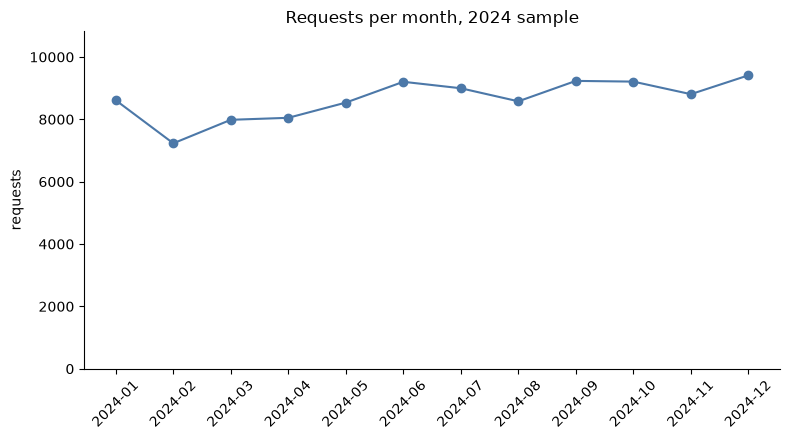

In [6]:
t5 = run("t05_monthly_trend")
display(t5.T)
fig, ax = plt.subplots()
ax.plot(t5["month"], t5["requests"], marker="o", color="#4c78a8")
ax.set_ylim(0, t5["requests"].max() * 1.15)
ax.set_ylabel("requests")
ax.set_title("Requests per month, 2024 sample")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Sample size:** 103,841 requests over 12 months (7,230 to 9,410 per month).
**Observed pattern:** February is the lowest month (7,230) and December the highest (9,410). From June to December the monthly count stays around 8,600 to 9,400.
**Interpretation:** February is a shorter month (29 days in 2024), so part of that dip is just fewer days. Demand looks a bit higher in the warmer and later months, but with one year of data we can not say it is a seasonal pattern.

## Task 6. Demand by weekday and hour
**Question:** when are requests created?
**Method:** group by weekday and hour of `created_date` (168 cells), shown as a heatmap.

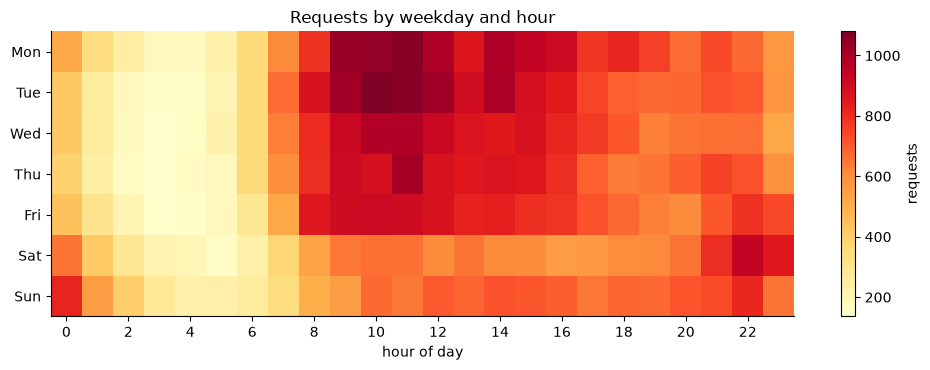

weekday
Monday       16274
Tuesday      15880
Wednesday    15006
Thursday     14828
Friday       14798
Saturday     13123
Sunday       13932

hour
11    6324
10    6227
12    5999
9     5998
14    5856


In [7]:
t6 = run("t06_weekday_hour")
grid = t6.pivot(index="weekday_num", columns="hour", values="requests")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(grid.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(7)); ax.set_yticklabels(days)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel("hour of day"); ax.set_title("Requests by weekday and hour")
fig.colorbar(im, label="requests")
plt.tight_layout()
plt.show()
print(t6.groupby("weekday", sort=False)["requests"].sum().to_string())
print()
print(t6.groupby("hour")["requests"].sum().sort_values(ascending=False).head(5).to_string())

**Sample size:** 103,841 requests, 168 weekday-hour cells.
**Observed pattern:** Monday is the busiest day (16,274) and Saturday the quietest (13,123). By hour, requests peak late morning (11:00 has 6,324) and are lowest at 3 to 4 am (about 1,230 per hour). There is an extra bump at midnight (3,670), higher than 1 to 5 am.
**Interpretation:** weekday office hours bring the most requests, which fits people reporting problems when they are awake and at work. The midnight bump may come from requests logged with a default time or from late-evening reports, we have not checked which. For staffing, the numbers suggest more coverage Monday to Friday between about 8 am and 4 pm.

## Task 7. Distribution of statuses
**Question:** what status do requests have now?
**Method:** group by `status`.

,status,requests,pct_of_all
0,Closed,102714,98.91
1,In Progress,776,0.75
2,Open,173,0.17
3,Pending,108,0.10
4,Assigned,53,0.05
5,Started,16,0.02
6,Unspecified,1,0.00


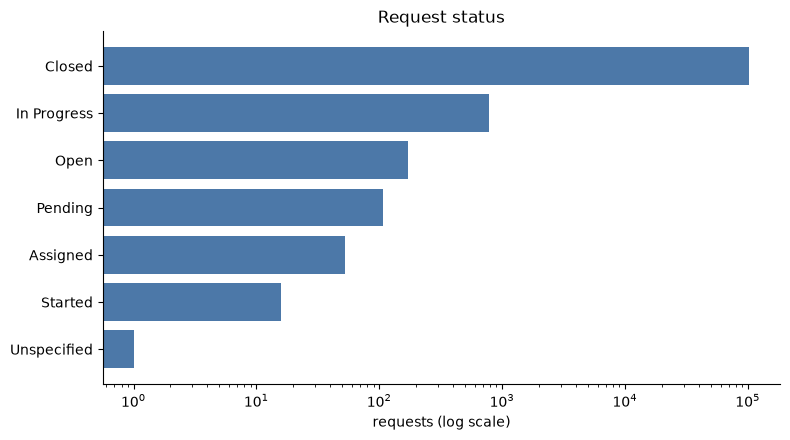

In [8]:
t7 = run("t07_status")
display(t7)
fig, ax = plt.subplots()
ax.barh(t7["status"][::-1], t7["requests"][::-1], color="#4c78a8")
ax.set_xscale("log")
ax.set_xlabel("requests (log scale)")
ax.set_title("Request status")
plt.tight_layout()
plt.show()

**Sample size:** 103,841 requests.
**Observed pattern:** 98.9% have status Closed. The other 1,127 are mostly In Progress (776) or Open (173).
**Interpretation:** almost everything from 2024 is closed by the extraction date (Nov 2026), which is a long time after the requests were created. Use a log scale here, otherwise the small groups are invisible. Status was read as of the extraction date, so a younger dataset would show many more open requests.

## Task 8. Descriptive statistics of resolution time
**Question:** how long do valid requests take to close?
**Method:** mean, median, quartiles, 95th percentile, min, max and standard deviation in SQL, with a pandas cross-check.

,hours
n_valid,101965.00
mean_h,332.61
median_h,8.20
min_h,0.00
q1_h,0.99
q3_h,82.72
p95_h,1712.06
max_h,24242.76
std_h,1256.84


pandas median: 8.2 | mean: 332.61 | n: 101965


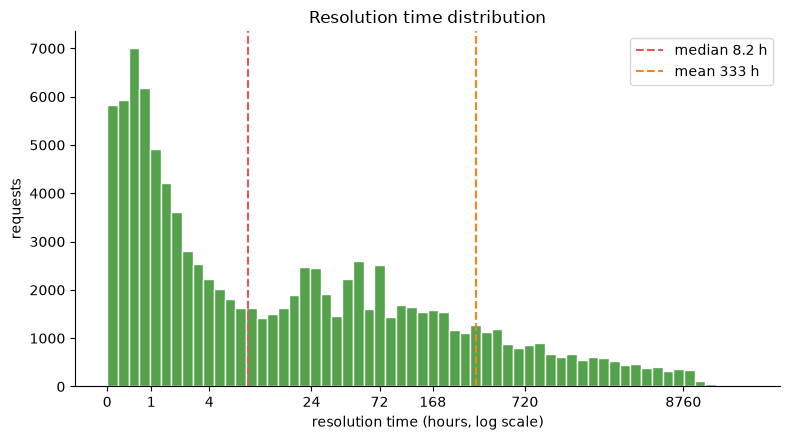

In [9]:
t8 = run("t08_resolution_stats")
display(t8.T.rename(columns={0: "hours"}))

# cross-check the SQL against pandas
res = pd.read_sql(text("SELECT resolution_hours FROM service_requests WHERE resolution_hours IS NOT NULL"), engine)["resolution_hours"]
print("pandas median:", round(res.median(), 2), "| mean:", round(res.mean(), 2), "| n:", len(res))
assert abs(res.median() - float(t8.loc[0, "median_h"])) < 0.01
assert abs(res.mean() - float(t8.loc[0, "mean_h"])) < 0.01

fig, ax = plt.subplots()
ax.hist(np.log1p(res), bins=60, color="#54a24b", edgecolor="white")
ticks = [0, 1, 4, 24, 72, 168, 720, 8760]
ax.set_xticks(np.log1p(ticks)); ax.set_xticklabels(ticks)
ax.axvline(np.log1p(res.median()), color="#e45756", linestyle="--", label=f"median {res.median():.1f} h")
ax.axvline(np.log1p(res.mean()), color="#f58518", linestyle="--", label=f"mean {res.mean():.0f} h")
ax.set_xlabel("resolution time (hours, log scale)"); ax.set_ylabel("requests"); ax.legend()
ax.set_title("Resolution time distribution")
plt.tight_layout()
plt.show()

**Sample size:** 101,965 requests with a valid resolution time.
**Observed pattern:** median 8.2 hours, mean 332.6 hours. A quarter of requests close within 1 hour (Q1 = 0.99), three quarters within 82.7 hours, and the 95th percentile is 1,712 hours (about 71 days). The longest is 24,243 hours (2.8 years).
**Interpretation:** the mean is about 40 times the median, so a small group of very long cases pulls the average up. The median describes a typical request better. SQL and pandas agree, which also checks the load.

## Task 9. Median resolution time by complaint category
**Question:** which categories take longest and shortest to close?
**Method:** `percentile_cont(0.5)` per complaint type, only types with at least 100 valid cases (83 of 171 types).

,complaint_type,n_valid,median_h,mean_h
0,New Tree Request,641,8089.40,7789.09
1,Mobile Food Vendor,207,4257.50,4269.56
2,Food Establishment,358,3235.02,3514.52
3,Root/Sewer/Sidewalk Condition,324,2734.69,3250.83
4,Smoking or Vaping,113,2697.37,3111.26
5,Building/Use,657,2222.38,3555.55
6,Taxi Complaint,182,2194.79,2377.54
7,For Hire Vehicle Complaint,678,2117.78,2286.45
8,Overgrown Tree/Branches,536,1100.04,2730.54
9,Noise - Helicopter,748,862.47,1283.93


,complaint_type,n_valid,median_h,mean_h
77,Noise - Park,250,0.55,1.34
78,Traffic,280,0.52,1.52
79,Drug Activity,690,0.43,1.12
80,Homeless Person Assistance,342,0.42,34.09
81,Bike/Roller/Skate Chronic,114,0.30,1.16
82,Rodent,1174,0.00,62.51


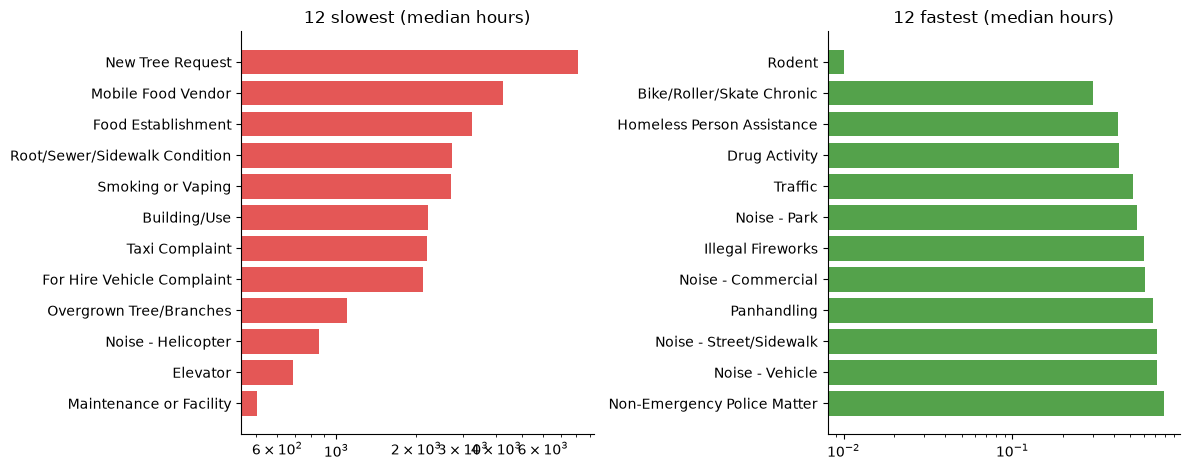

,complaint_type,zero_hour_requests
0,Rodent,680
1,Water System,316
2,General Construction/Plumbing,152
3,Street Condition,119
4,Real Time Enforcement,78


In [10]:
t9 = run("t09_median_by_complaint")
display(t9.head(10))
display(t9.tail(6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
top = t9.head(12)[::-1]
axes[0].barh(top["complaint_type"], top["median_h"], color="#e45756")
axes[0].set_title("12 slowest (median hours)"); axes[0].set_xscale("log")
bot = t9.tail(12)
axes[1].barh(bot["complaint_type"], bot["median_h"].clip(lower=0.01), color="#54a24b")
axes[1].set_title("12 fastest (median hours)"); axes[1].set_xscale("log")
plt.tight_layout()
plt.show()

# rodent shows a median of exactly 0, check why
zero = pd.read_sql(text("SELECT complaint_type, COUNT(*) AS zero_hour_requests FROM service_requests "
                        "WHERE resolution_hours = 0 GROUP BY 1 ORDER BY 2 DESC LIMIT 5"), engine)
display(zero)

**Sample size:** 83 complaint types with 100 or more valid cases (the other 88 types are left out as too small).
**Observed pattern:** New Tree Request is far the slowest (median 8,089 hours, about 11 months). Next are Mobile Food Vendor (4,258 h), Food Establishment (3,235 h) and Root/Sewer/Sidewalk Condition (2,735 h). The fastest are police-type complaints (Drug Activity 0.43 h, Traffic 0.52 h) and Rodent, whose median is exactly 0.
**Interpretation:** slow categories are mostly scheduled or inspection-based work (trees, licences, permits), fast ones are quick police responses. The Rodent median of 0 is suspicious: 680 Rodent requests have a closed date equal to the created date. This may be how inspection requests are recorded rather than a real zero-hour response, so Rodent should not be read as "fastest" without checking with the data owner. These are recorded durations, not service quality.

## Task 10. Median resolution time by agency
**Question:** how do agencies compare on typical closing time?
**Method:** `percentile_cont(0.5)` per agency (at least 100 valid cases).

,agency,n_valid,median_h,mean_h
0,TLC,1087,1726.04,1855.03
1,EDC,748,862.47,1283.93
2,DPR,3767,667.31,2881.19
3,DOB,3072,339.26,1657.44
4,HPD,21893,93.58,341.07
5,DCWP,611,93.20,360.50
6,DOT,6007,43.31,327.02
7,DSNY,9175,29.84,137.92
8,DEP,5727,25.22,133.05
9,DOHMH,2580,24.00,1164.59


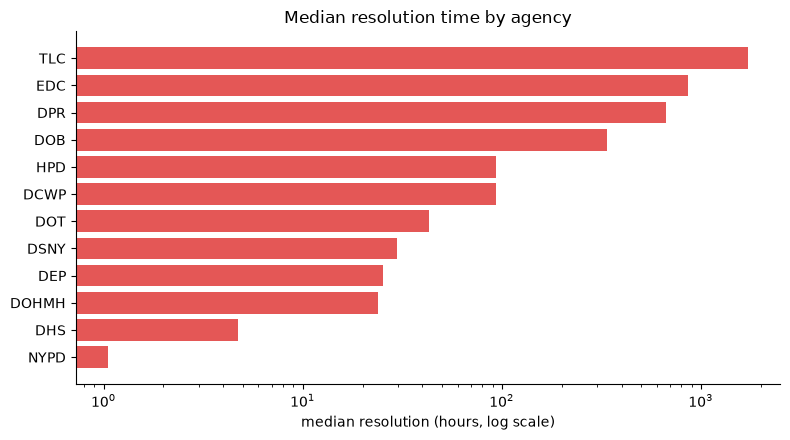

In [11]:
t10 = run("t10_median_by_agency")
display(t10)
fig, ax = plt.subplots()
ax.barh(t10["agency"][::-1], t10["median_h"][::-1], color="#e45756")
ax.set_xscale("log")
ax.set_xlabel("median resolution (hours, log scale)")
ax.set_title("Median resolution time by agency")
plt.tight_layout()
plt.show()

**Sample size:** 12 agencies, 101,965 valid requests in total.
**Observed pattern:** TLC is the slowest (median 1,726 h, about 72 days), then EDC (862 h) and DPR (667 h). NYPD is the fastest at 1.05 hours. HPD, the second-largest agency, has a median of 93.6 hours.
**Interpretation:** agencies deal with very different work (a police response versus a housing repair or a licence process), so this is not a performance ranking. It is useful for planning: it shows where long waits are normal for the type of work.

## Task 11. IQR outlier investigation
**Question:** which resolution times are unusually long, and where do they come from?
**Method:** Q1, Q3, IQR, fences at Q1 - 1.5 x IQR and Q3 + 1.5 x IQR, then outliers by agency. Outliers are flagged, not removed.

,q1_h,q3_h,iqr_h,lower_fence_h,upper_fence_h,high_outliers,low_outliers,n_valid
0,0.99,82.72,81.72,-121.59,205.3,17001,0,101965


,agency,n_valid,high_outliers,pct_outliers
0,HPD,21893,7068,32.3
1,DPR,3767,2353,62.5
2,DOB,3072,1696,55.2
3,DOT,6007,1295,21.6
4,DOHMH,2580,933,36.2
5,DSNY,9175,904,9.9
6,TLC,1087,867,79.8
7,DEP,5727,770,13.4
8,EDC,748,718,96.0
9,DCWP,611,265,43.4


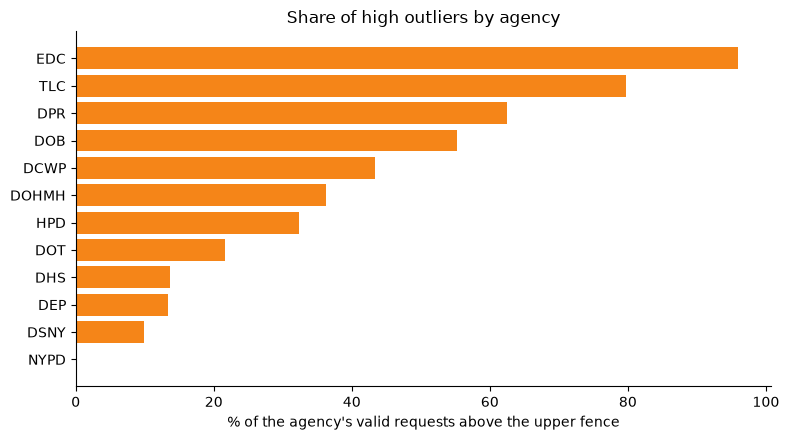

In [12]:
t11 = run("t11_outlier_fences")
display(t11)
t11b = run("t11_outliers_by_agency")
display(t11b)
fig, ax = plt.subplots()
d = t11b.sort_values("pct_outliers")
ax.barh(d["agency"], d["pct_outliers"], color="#f58518")
ax.set_xlabel("% of the agency's valid requests above the upper fence")
ax.set_title("Share of high outliers by agency")
plt.tight_layout()
plt.show()

**Sample size:** 101,965 valid requests; agencies with at least 200 valid cases.
**Observed pattern:** Q1 = 0.99 h, Q3 = 82.72 h, IQR = 81.72 h. The lower fence is negative (-121.6 h), so no low outliers can exist. The upper fence is 205.3 h (8.6 days) and 17,001 requests (16.7%) are above it. HPD has the most (7,068), but proportionally EDC (96%), TLC (80%) and DPR (62%) are highest. NYPD has only 1.
**Interpretation:** 16.7% flagged is a lot because the distribution is so skewed that the IQR rule marks many ordinary long cases. Outliers here are mostly work that normally takes weeks (repairs, inspections, permits), so they are prompts to look closer, not errors. We kept them all.

## Task 12. Skewness and distribution
**Question:** how skewed is resolution time, and what does the distribution look like in bands?
**Method:** moment skewness in SQL plus counts in time bands.

,skewness,mean_h,median_h
0,6.7,332.61,8.2


,band,requests,pct
0,1) under 1 hour,25618,25.1
1,2) 1 to 4 hours,18677,18.3
2,3) 4 to 24 hours,17225,16.9
3,4) 1 to 3 days,13154,12.9
4,5) 3 to 7 days,8336,8.2
5,6) 7 to 30 days,10060,9.9
6,7) over 30 days,8895,8.7


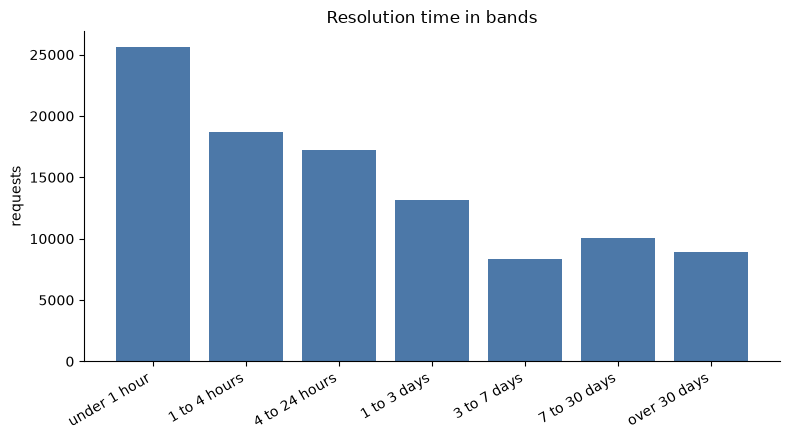

scipy skewness: 6.7 | after log1p: 0.74


In [13]:
t12 = run("t12_skewness")
display(t12)
t12b = run("t12_distribution")
display(t12b)
fig, ax = plt.subplots()
ax.bar(t12b["band"].str[3:], t12b["requests"], color="#4c78a8")
ax.set_ylabel("requests"); ax.set_title("Resolution time in bands")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

from scipy import stats
print("scipy skewness:", round(stats.skew(res), 2), "| after log1p:", round(stats.skew(np.log1p(res)), 2))

**Sample size:** 101,965 valid requests.
**Observed pattern:** skewness is 6.7 (SQL and scipy agree), far above 0, so the right tail is very long. Bands: 25.1% close in under an hour, 43.4% within 4 hours, 73.2% within 3 days (the first four bands added up), and 8.7% take over 30 days. After a log transform the skewness falls to 0.74.
**Interpretation:** most requests close quickly, but a visible minority take months. That is why mean and median differ so much. Reports should show the median and the share over a threshold, not just the average.

## Task 13. Geographic concentration
**Question:** where are requests concentrated, and how usable are the coordinates?
**Method:** coverage of coordinates by borough, then counts per 0.01-degree grid cell (about 1 km), then a check of the busiest cell.

,borough,requests,with_coordinates,pct_with_coordinates
0,BROOKLYN,31479,31111,98.8
1,QUEENS,24831,24287,97.8
2,BRONX,22305,22106,99.1
3,MANHATTAN,21481,21235,98.9
4,STATEN ISLAND,3657,3570,97.6
5,UNSPECIFIED,88,6,6.8


,lat_cell,lon_cell,requests,borough,top_complaint
0,40.89,-73.86,2199,BRONX,Noise - Residential
1,40.82,-73.94,860,MANHATTAN,HEAT/HOT WATER
2,40.78,-73.98,736,MANHATTAN,Noise - Helicopter
3,40.86,-73.90,712,BRONX,HEAT/HOT WATER
4,40.82,-73.95,711,MANHATTAN,Noise - Street/Sidewalk
5,40.85,-73.91,674,BRONX,HEAT/HOT WATER
6,40.65,-73.96,643,BROOKLYN,HEAT/HOT WATER
7,40.76,-73.99,623,MANHATTAN,Homeless Person Assistance
8,40.87,-73.90,622,BRONX,HEAT/HOT WATER
9,40.73,-74.00,621,MANHATTAN,Encampment


,latitude,longitude,requests,top_complaint,address
0,40.891872,-73.860168,1701,Noise - Residential,655 EAST 230 STREET
1,40.721959,-73.809697,210,Drug Activity,78-15 PARSONS BOULEVARD
2,40.717250,-73.803433,188,Drug Activity,82-68 164 STREET
3,40.891820,-73.860009,166,Noise - Residential,661 EAST 230 STREET
4,40.836941,-73.903744,138,Noise - Residential,1465 WASHINGTON AVENUE


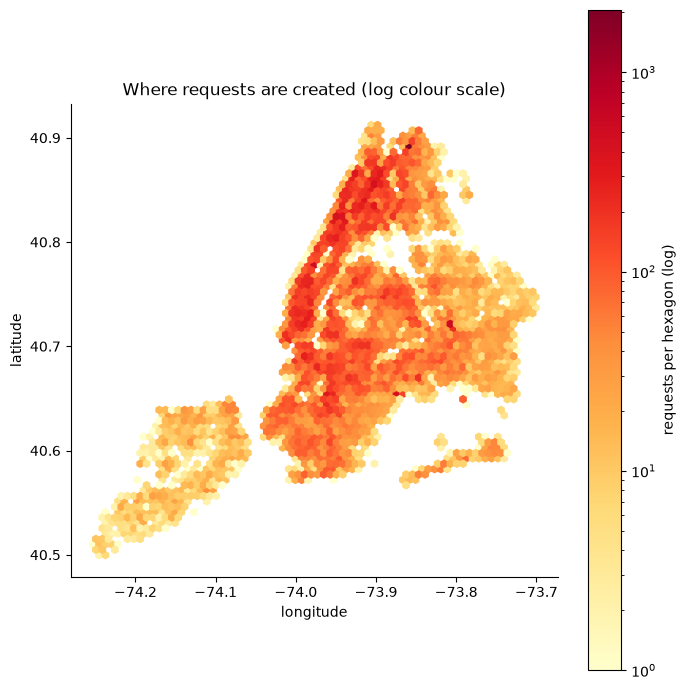

In [14]:
t13a = run("t13_geo_by_borough")
display(t13a)
t13b = run("t13_geo_hotspots")
display(t13b)
t13c = run("t13_hotspot_exact")
display(t13c)

pts = pd.read_sql(text("SELECT latitude, longitude, borough FROM service_requests WHERE NOT flag_missing_coordinates"), engine)
fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(pts["longitude"], pts["latitude"], gridsize=70, bins="log", cmap="YlOrRd", mincnt=1)
ax.set_aspect(1.3); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Where requests are created (log colour scale)")
fig.colorbar(hb, label="requests per hexagon (log)")
plt.tight_layout()
plt.show()

**Sample size:** 102,315 requests with coordinates (98.5%). 1,526 rows have no coordinates and are left out of the map.
**Observed pattern:** coverage is about 98 to 99% in every borough except UNSPECIFIED (6.8%). The busiest 1 km cell is in the Bronx (40.89, -73.86) with 2,199 requests, more than double the next one (860, Manhattan). One exact coordinate in that cell, at 655 East 230 Street, holds 1,701 requests, mostly Illegal Parking. Other busy cells are in northern Manhattan and the Bronx (heat and hot water complaints) and Manhattan (helicopter noise, homeless assistance, encampments).
**Interpretation:** the single huge point looks like a default location for many requests, perhaps a police facility, not 1,701 separate problems on one block. We have not confirmed this. Hot spots like this should be removed or handled separately before using the map for planning. Without it, concentration follows dense areas (northern Manhattan, the Bronx, parts of Brooklyn).

## Task 14. Recorded closure rate comparison
**Question:** which agencies and boroughs have the lowest and highest share of requests with a closed date?
**Method:** `SUM(is_closed) / COUNT(*)` by agency (at least 500 requests) and by borough, with the status-based rate next to it.

,agency,requests,closed,closure_rate_pct,status_closed_pct
0,DHS,1511,706,46.72,100.00
1,EDC,852,748,87.79,87.79
2,DPR,4199,3767,89.71,89.71
3,TLC,1156,1087,94.03,94.03
4,DOHMH,2692,2580,95.84,95.80
5,DCWP,632,611,96.68,96.68
6,DOT,6136,6030,98.27,97.77
7,DEP,5790,5727,98.91,98.91
8,HPD,21994,21893,99.54,99.54
9,DSNY,9213,9175,99.59,99.59


,borough,requests,closed,closure_rate_pct
0,MANHATTAN,21481,20707,96.40
1,UNSPECIFIED,88,85,96.59
2,QUEENS,24831,24384,98.20
3,STATEN ISLAND,3657,3604,98.55
4,BROOKLYN,31479,31033,98.58
5,BRONX,22305,22177,99.43


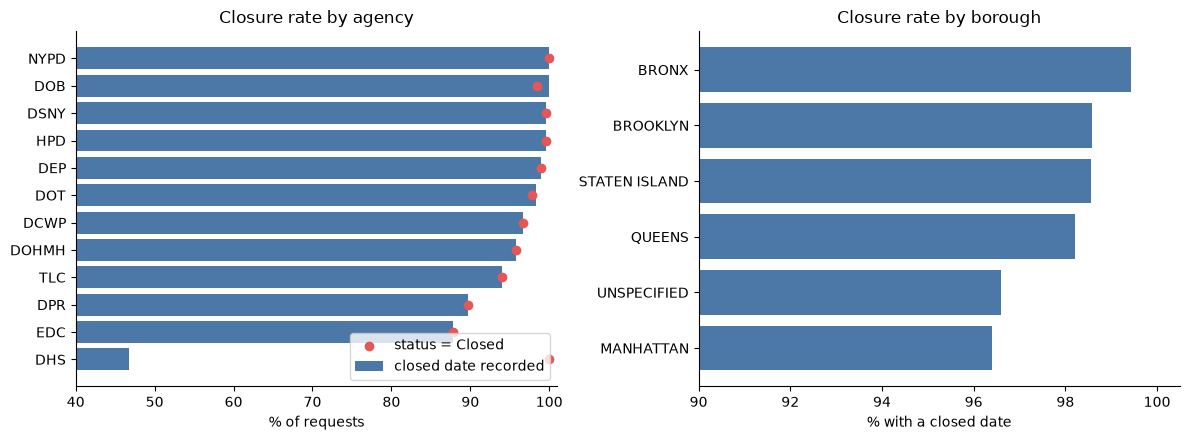

In [15]:
t14a = run("t14_closure_by_agency")
display(t14a)
t14b = run("t14_closure_by_borough")
display(t14b)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(t14a["agency"], t14a["closure_rate_pct"], color="#4c78a8", label="closed date recorded")
axes[0].scatter(t14a["status_closed_pct"], t14a["agency"], color="#e45756", zorder=3, label="status = Closed")
axes[0].set_xlim(40, 101); axes[0].set_xlabel("% of requests"); axes[0].set_title("Closure rate by agency"); axes[0].legend(loc="lower right")
axes[1].barh(t14b["borough"], t14b["closure_rate_pct"], color="#4c78a8")
axes[1].set_xlim(90, 100.5); axes[1].set_xlabel("% with a closed date"); axes[1].set_title("Closure rate by borough")
plt.tight_layout()
plt.show()

**Sample size:** 12 agencies with at least 500 requests, 5 boroughs plus UNSPECIFIED.
**Observed pattern:** the recorded closure rate is 100% for NYPD and DOB, 99.5% or more for DSNY and HPD, and lowest for DHS (46.7%), then EDC (87.8%) and DPR (89.7%). By borough the range is narrow: Manhattan 96.4% is lowest, Bronx 99.4% highest.
**Interpretation:** DHS looks far behind, but all 1,511 DHS requests have status Closed. They just have no closed date in the data, so the low rate is a recording gap, not open work. This is exactly why recorded closure must not be read as performance. Manhattan's lower rate is small and could reflect different complaint mix.

## Task 15. High volume and long median resolution
**Question:** which complaint types are both common and slow?
**Method:** per complaint type (at least 100 valid cases): request count and median resolution. "High" means at or above the 75th percentile of types for each measure.

volume cut: 1181.0 | median cut (h): 229.04


,complaint_type,requests,n_valid,median_h,volume_cut,median_cut_h,high_volume_and_slow
0,DOOR/WINDOW,1379,1379,261.26,1181.0,229.04,True
1,WATER LEAK,1339,1338,241.69,1181.0,229.04,True


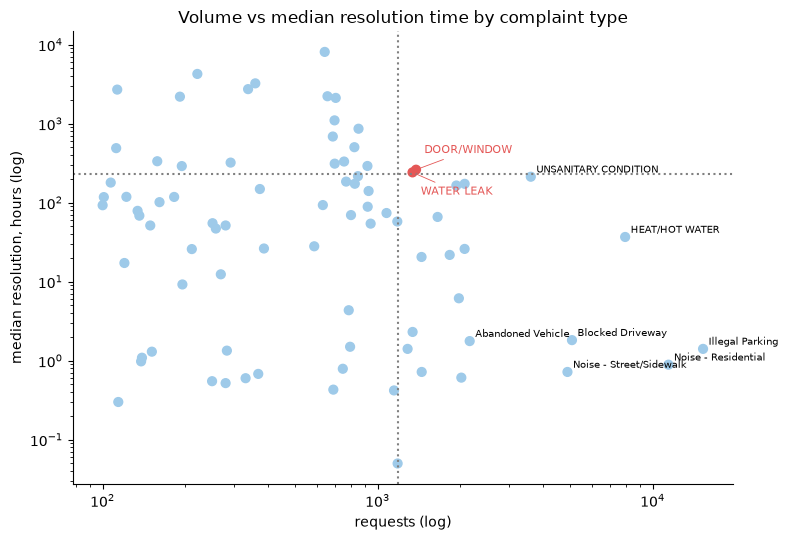

In [16]:
t15 = run("t15_volume_vs_resolution")
vol_cut = float(t15["volume_cut"].iloc[0]); med_cut = float(t15["median_cut_h"].iloc[0])
print("volume cut:", vol_cut, "| median cut (h):", med_cut)
display(t15[t15["high_volume_and_slow"]])

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = np.where(t15["high_volume_and_slow"], "#e45756", "#9ecae9")
ax.scatter(t15["requests"], t15["median_h"].clip(lower=0.05), c=colors, s=40)
ax.axvline(vol_cut, color="grey", linestyle=":"); ax.axhline(med_cut, color="grey", linestyle=":")
ax.set_xscale("log"); ax.set_yscale("log")
for _, r in t15[~t15["high_volume_and_slow"]].sort_values("requests", ascending=False).head(7).iterrows():
    ax.annotate(r["complaint_type"], (r["requests"], max(r["median_h"], 0.05)), fontsize=7, xytext=(4, 3), textcoords="offset points")
offsets = [(6, 12), (6, -16)]   # the two points sit almost on top of each other, so split the labels
for off, (_, r) in zip(offsets, t15[t15["high_volume_and_slow"]].iterrows()):
    ax.annotate(r["complaint_type"], (r["requests"], r["median_h"]), fontsize=8, color="#e45756",
                xytext=off, textcoords="offset points", arrowprops={"arrowstyle": "-", "color": "#e45756", "lw": 0.6})
ax.set_xlabel("requests (log)"); ax.set_ylabel("median resolution, hours (log)")
ax.set_title("Volume vs median resolution time by complaint type")
plt.tight_layout()
plt.show()

**Sample size:** 83 complaint types. Cut-offs: 1,181 requests (75th percentile of volume) and 229.0 hours (75th percentile of median time).
**Observed pattern:** only two types are both high in volume and slow: DOOR/WINDOW (1,379 requests, median 261 h) and WATER LEAK (1,339 requests, median 242 h). Several others come close: UNSANITARY CONDITION (3,605 requests, 213 h) and PLUMBING (2,072 requests, 173 h). The biggest categories by volume, Illegal Parking and Noise - Residential, are quick (medians 1.4 h and 0.9 h).
**Interpretation:** the heavy and slow part of the workload is housing maintenance (HPD): doors, windows, leaks, plumbing and unsanitary conditions. These are the best candidates for operational attention, because they are common and take more than a week at the median. The two-type result depends on the 75th-percentile cut, so a lower threshold would add UNSANITARY CONDITION and PLUMBING. This is a pattern in recorded times, not proof of poor service.

## Limitations
- ~3% systematic sample of one year; counts are not citywide totals.
- Status and closed dates are as of 11 Nov 2026. Requests can be reopened or updated later.
- Closure is a recorded date, not satisfaction or verified resolution. Some records say Closed but have no closed date (805), and 1,695 have a resolution of exactly 0 hours.
- Agencies and complaint types differ in complexity, so comparisons between them are not fair rankings.
- Raw counts are not adjusted for population or area.